Loading data...
Before SMOTE, training target distribution:
Churn
0    4130
1    1495
Name: count, dtype: int64
After SMOTE, training target distribution:
Churn
1    4130
0    4130
Name: count, dtype: int64

Training Random Forest and XGBoost...


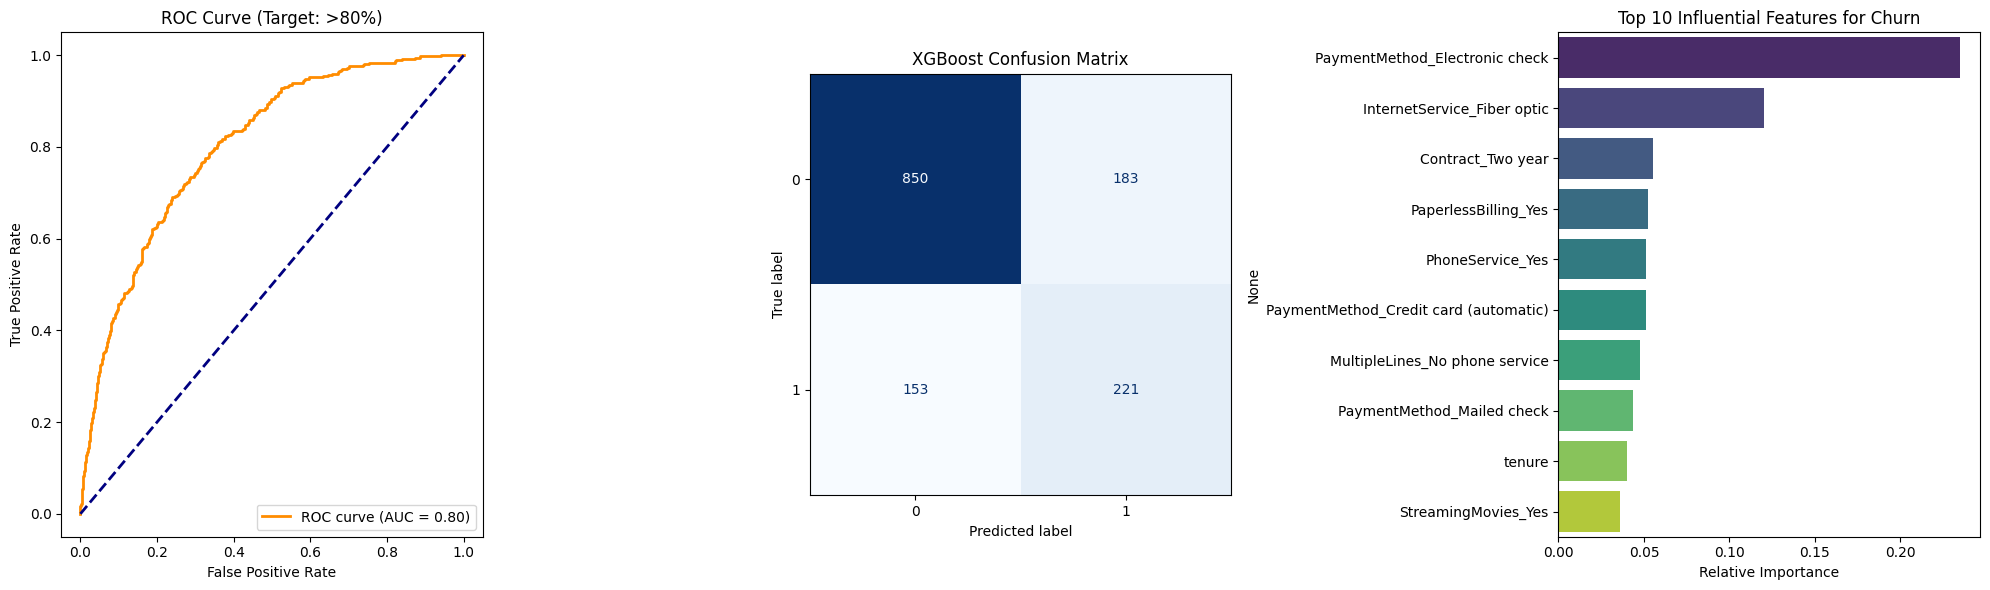


--- Classification Report (XGBoost) ---
              precision    recall  f1-score   support

           0       0.85      0.82      0.83      1033
           1       0.55      0.59      0.57       374

    accuracy                           0.76      1407
   macro avg       0.70      0.71      0.70      1407
weighted avg       0.77      0.76      0.76      1407



In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_curve, auc, ConfusionMatrixDisplay
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
import warnings
warnings.filterwarnings('ignore')

# 1. Load the Telco Customer Churn Dataset
print("Loading data...")
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

# 2. Preprocess: Convert TotalCharges to numeric and handle nulls
# Some 'TotalCharges' are blank spaces. We force them to NaN (null), then drop those rows.
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df.dropna(subset=['TotalCharges'], inplace=True)

# Drop the customerID column as it is useless for math
df.drop('customerID', axis=1, inplace=True)

# 3. Categorical Preprocessing (OneHotEncoding via Pandas get_dummies)
# Map the Target 'Churn' to 1 (Yes) and 0 (No)
y = df['Churn'].map({'Yes': 1, 'No': 0})
X = df.drop('Churn', axis=1)

# Convert all text columns into 1s and 0s
X_encoded = pd.get_dummies(X, drop_first=True)

# 4. Train/Test Split & Balance Classes with SMOTE
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)

print(f"Before SMOTE, training target distribution:\n{y_train.value_counts()}")
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)
print(f"After SMOTE, training target distribution:\n{y_train_smote.value_counts()}")

# 5. Train Ensemble Classifiers
print("\nTraining Random Forest and XGBoost...")
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train_smote, y_train_smote)

xgb_model = XGBClassifier(random_state=42, eval_metric='logloss')
xgb_model.fit(X_train_smote, y_train_smote)

# We will use XGBoost for the final deliverables as it usually yields higher performance
xgb_preds = xgb_model.predict(X_test)
xgb_probs = xgb_model.predict_proba(X_test)[:, 1] # Get probabilities for ROC curve

# --- GENERATE EXPECTED DELIVERABLES ---
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Deliverable A: ROC-AUC Curve
fpr, tpr, thresholds = roc_curve(y_test, xgb_probs)
roc_auc = auc(fpr, tpr)
axes[0].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
axes[0].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curve (Target: >80%)')
axes[0].legend(loc="lower right")

# Deliverable B: Confusion Matrix
ConfusionMatrixDisplay.from_predictions(y_test, xgb_preds, ax=axes[1], cmap='Blues', colorbar=False)
axes[1].set_title('XGBoost Confusion Matrix')

# Deliverable C: Top 10 Feature Importance Bar Chart
importances = xgb_model.feature_importances_
indices = np.argsort(importances)[::-1][:10] # Get top 10
top_features = X_train_smote.columns[indices]

sns.barplot(x=importances[indices], y=top_features, ax=axes[2], palette="viridis")
axes[2].set_title('Top 10 Influential Features for Churn')
axes[2].set_xlabel('Relative Importance')

plt.tight_layout()
plt.show()

print("\n--- Classification Report (XGBoost) ---")
print(classification_report(y_test, xgb_preds))